# 航空部件非计划拆换预测 PoC

目标：未来 30 个飞行循环内的非计划拆换。主要门槛为事件级召回率 ≥ 80%，逐轮及总体警报率 ≤ 5%。本 Notebook 只读取冻结数据与实验产物，不参与阈值或模型选择。

In [1]:
from pathlib import Path
import os
if Path.cwd().name == 'notebooks':
    os.chdir(Path.cwd().parent)
import json
import pandas as pd
import matplotlib.pyplot as plt
from src.splitter import create_joint_split_manifest, entity_group_diagnostics

DATA_DIR = Path('data/generated/mock_v0_2_0')
data = pd.read_parquet(DATA_DIR / 'mro_dataset.parquet')
manifest = json.loads((DATA_DIR / 'manifest.json').read_text(encoding='utf-8'))
manifest['summary']

{'dataset_version': '0.2.0',
 'seed': 20261112,
 'prediction_horizon_cycles': 30,
 'snapshot_interval_cycles': 5,
 'rows': {'aircraft': 60,
  'components': 723,
  'component_snapshots': 114989,
  'sensor_readings': 114989,
  'fault_events': 3683,
  'maintenance_events': 2133,
  'removal_events': 484,
  'labels': 114989,
  'mro_dataset': 114989},
 'aircraft': 60,
 'components': 723,
 'removals_by_type': {'UNSCHEDULED': 404, 'SCHEDULED': 80},
 'labeled_snapshots': 113090,
 'censored_snapshots': 1899,
 'positive_snapshots': 2424,
 'positive_snapshot_rate': 0.021434255902378636,
 'unscheduled_events_with_positive_snapshot': 404}

## EDA：正例率、缺失、异常和实体/事件规模

In [2]:
eda = pd.DataFrame({
    'missing_rate': data[['vibration_rms', 'egt_margin', 'sensor_temperature', 'sensor_pressure', 'sensor_current']].isna().mean(),
})
display(eda)
data['unscheduled_removal_within_30_cycles'].value_counts(dropna=False, normalize=True)

,missing_rate
vibration_rms,0.057519
egt_margin,0.764543
sensor_temperature,0.058319
sensor_pressure,0.211394
sensor_current,0.058493


unscheduled_removal_within_30_cycles
0       0.962405
1        0.02108
<NA>    0.016515
Name: proportion, dtype: Float64

## 联合时间/飞机/部件划分与泄漏证据

In [3]:
split = create_joint_split_manifest(
    data, train_end='2024-09-01', validation_end='2025-09-01', calibration_end='2025-03-01'
)
display(split.groupby(['outer_partition', 'final_use']).size())
display(entity_group_diagnostics(split).head())

outer_partition  final_use  
test             excluded       17102
                 test            5895
train            excluded       32743
                 train          36252
validation       calibration     2002
                 excluded       18601
                 policy          2394
dtype: int64

,entity_group_id,snapshots,aircraft,components,events,snapshot_share
0,EG00054,1919,1,9,0,0.016689
1,EG00034,1919,1,11,0,0.016689
2,EG00009,1918,1,10,0,0.016680
3,EG00010,1918,1,13,0,0.016680
4,EG00041,1918,1,10,0,0.016680


## PR 曲线、校准与阈值分析

读取冻结的验证候选和最终测试结果。测试数据已在独立脚本中完成一次评估，此处仅展示，不参与模型或策略选择。

,candidate_id,event_recall,alert_rate,false_positives_per_100,pr_auc,brier_score,threshold
0,logistic_unweighted,0.9375,0.006683,0.000000,0.988964,0.005375,0.263584
1,logistic_balanced,1.0000,0.008354,0.125313,0.987477,0.005722,0.134128
2,lightgbm_unweighted,1.0000,0.007101,0.000000,0.981026,0.003985,0.725024
3,lightgbm_balanced,1.0000,0.007101,0.000000,0.980028,0.004295,0.823542


{'freeze_manifest_sha256': 'f17eed0cf9c54d6bb266807e8e69bf6ee2fa83ca56ca35ea2de9c223ddaacc74',
 'frozen_model_sha256': 'e2465f451ed3b33e32f916d00386e00ee6cfd621423828fb415e043323f5cbb2',
 'candidate_id': 'lightgbm_unweighted',
 'threshold': 0.7250242783616677,
 'suppression_cycles': 30,
 'alert_rate': 0.00542832909245123,
 'alerts_per_100': 0.542832909245123,
 'false_positives_per_100': 0.033927056827820185,
 'precision': 0.9090909090909091,
 'snapshot_recall': 0.1724137931034483,
 'pr_auc': 0.9854730573560142,
 'event_recall': 1.0,
 'pending_outcome_alerts': 10,
 'scored_components': 5895,
 'labeled_components': 5565,
 'batches': 123,
 'overall_alert_rate': 0.00542832909245123,
 'max_batch_alert_rate': 0.041666666666666664,
 'over_capacity_batches': 0,
 'capacity_deferred': 0,
 'suppressed': 122,
 'brier_score': 0.0021124365346015233,
 'roc_auc': 0.999631378107973,
 'actual_unscheduled_events': 20,
 'detected_events': 20,
 'mean_first_alert_lead_cycles': 22.8,
 'median_first_alert_lea

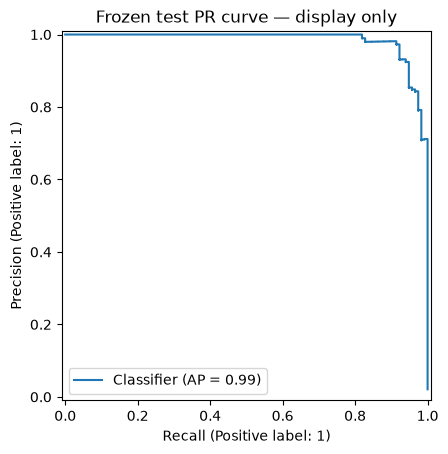

In [4]:
EXPERIMENT = Path('artifacts/experiments/validation_v1')
TEST = Path('artifacts/frozen_test/validation_v1')
candidates = pd.read_csv(EXPERIMENT / 'validation_candidate_metrics.csv')
display(candidates[['candidate_id', 'event_recall', 'alert_rate', 'false_positives_per_100', 'pr_auc', 'brier_score', 'threshold']])
test_metrics = json.loads((TEST / 'test_metrics.json').read_text(encoding='utf-8'))
display(test_metrics)
from sklearn.metrics import PrecisionRecallDisplay
test_predictions = pd.read_parquet(TEST / 'test_predictions.parquet')
labeled = test_predictions.dropna(subset=['unscheduled_removal_within_30_cycles'])
PrecisionRecallDisplay.from_predictions(
    labeled['unscheduled_removal_within_30_cycles'].astype(int), labeled['risk_score']
)
plt.title('Frozen test PR curve — display only')
plt.show()

## SHAP 与高风险解释卡

LightGBM 使用原始 log-odds 归因并检查加和关系；展示时单独报告校准概率。包含两个高风险部件和一个误报案例；冻结测试没有漏报事件。

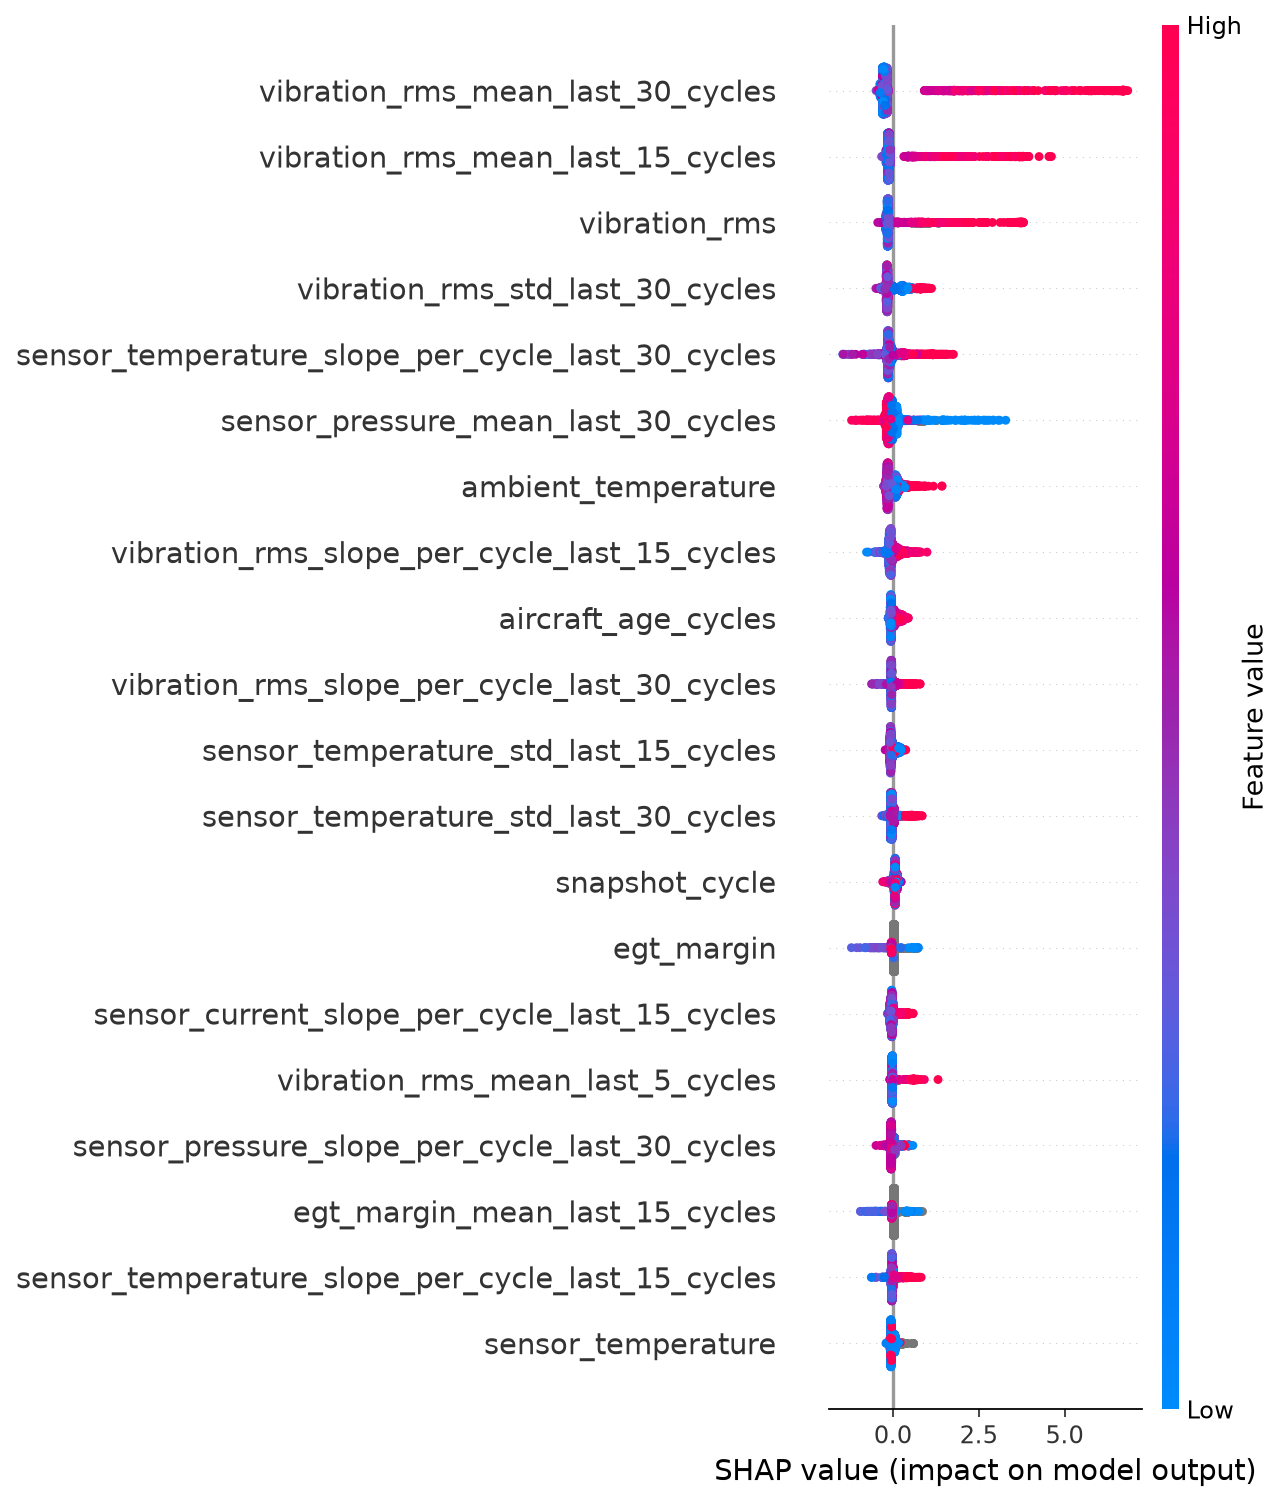

# 高风险部件 SHAP 解释卡

SHAP 贡献对应 LightGBM 原始 log-odds；风险分数为校准及冷启动混合后的概率。模型归因不等于物理根因。

## 案例 1：C0000481

- 飞机：AC0040；部件族：HYDRAULIC_PUMP；型号：HYD-B2
- 快照：S00075612；批次：BATCH-2026-01-28
- 风险分数：0.996339；冻结阈值：0.725024
- 实际标签：1；关联拆换事件：REM0000325

| 排名 | 主要因素 | 当前值 | 方向 | 原始分数贡献 | 建议检查 |
| ---: | --- | ---: | --- | ---: | --- |
| 1 | 振动有效值（相关特征合并） | 3.5521 | 推高风险 | +16.44100 | 检查振动、轴承及转动部件，并复核传感器通道。 |
| 2 | 部件温度（相关特征合并） | 0.7991 | 推高风险 | +2.39325 | 检查冷却、热负荷和温度传感器读数。 |
| 3 | 部件压力（相关特征合并） | -0.4951 | 推高风险 | +0.67208 | 检查压力异常、泄漏和压力传感器。 |

**MRO 建议：** 安排针对性检查并核实传感器、故障和维修证据；不得仅凭评分直接拆换部件。

## 案例 2：C0000478

- 飞机：AC0040；部件族：ENGINE；型号：ENG-A1
- 快照：S00075094；批次：BATCH-2025-09-04
- 风险分数：0.995741；冻结阈值：0.725024
- 实际标签：1；关联拆换事件：REM0000323

| 排名 | 主要因素 | 当前值 | 方向 | 原始分数贡献 | 建议检查 |
| ---: | --- | ---: | --- | ---: | --- |
| 1 | 振动有效值（相关特征合并） | 3.2953 | 推高风险 | +16.35913 | 检查振动、轴承及转动部件，并复核传感器通道。 |
| 2 | 部件温度（相关特征合并） | 0.5329 | 推高风险 | +2.15073 | 检查冷却、热负荷和温度传感器读数。 |
| 3 | 排气温度裕度（相关特征合并） | 35.6728 | 推高风险 | +1.57197 | 检查发动机热端、EGT裕度趋势及相关传感器。 |

**MRO 建议：** 安排针对性检查并核实传感器、故障和维修证据；不得仅凭评分直接拆换部件。


误报部件 C0000481：风险 0.8499，实际标签 0。

In [5]:
from IPython.display import Image, Markdown
display(Image(filename='reports/figures/shap_summary.png'))
display(Markdown(Path('reports/high_risk_cards.md').read_text(encoding='utf-8')))
false_positive = json.loads(Path('reports/false_positive_card.json').read_text(encoding='utf-8'))
display(Markdown(f"误报部件 {false_positive['component_id']}：风险 {false_positive['risk_score']:.4f}，实际标签 0。"))

## 生产闭环与局限

航后数据接入 → 可用时间过滤 → 时点特征 → 风险评分与 SHAP → 重复抑制及逐轮容量 → AMOS/Maximo 工单队列 → 30 循环延迟标签回流 → 漂移监控、审批重训练与回滚。合成数据结果不代表真实机队性能。